# 01 · Exploración del conjunto de datos (EDA)

**TFM:** Predicción temprana del abandono en educación superior con datos de matrícula y modelos de ensamble frente a reglas tradicionales.

**Propósito.** Describir el conjunto de datos *Predict Students' Dropout and Academic Success* (UCI, id 697) y comprobar las cifras y decisiones que se citan en la memoria. Este notebook **no entrena modelos** ni selecciona variables: solo describe los datos.

| Sección | Pregunta | Uso en la memoria |
|---|---|---|
| 1 | ¿El archivo local coincide con la fuente? | 1.2, Anexo de datos |
| 2 | ¿Cómo se distribuye la variable objetivo? | 2.1, 2.2.3 |
| 3 | ¿Qué variables entran en cada escenario (E1, E1+, E2, E3)? | 1.2, 3.2, 3.3 |
| 4 | ¿Qué subgrupos permiten evaluar equidad y con qué tamaño? | 2.2.4, 3.2 |
| 5 | ¿Hay registros anómalos que afecten a la regla tradicional? | 3.3, Capítulo 4 |
| 6 | ¿Qué representan las variables macroeconómicas? | 1.2 |
| 7 | ¿Cuántos ingresos son traslados o cambios de titulación? | 2.1 (perspectiva micro) |
| 8 | ¿Qué variables discriminan por sí solas? | 3.3 (justificación de la regla) |
| 9 | Resumen de hallazgos | — |

## 0. Configuración

Rutas, semilla y librerías. La copia local del CSV es la fuente de trabajo; la descarga desde la UCI es opcional y solo sirve para contrastar.

In [1]:
# 0.1 Librerías y rutas
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

SEED = 42
COMPARAR_CON_UCI = False  # True descarga la versión oficial con ucimlrepo (requiere red)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "README.md").exists())
DATA = ROOT / "TFM2" / "Datos" / "predict+students+dropout+and+academic+success" / "data.csv"

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)
print(DATA.relative_to(ROOT))

TFM2/Datos/predict+students+dropout+and+academic+success/data.csv


## 1. Carga y verificación de integridad

El CSV de la UCI usa `;` como separador, viene con BOM UTF-8 y una columna trae un tabulador al final del nombre (`Daytime/evening attendance\t`). Se limpian los nombres sin tocar los valores.

In [2]:
# 1.1 Carga del CSV local
df = pd.read_csv(DATA, sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

sha256 = hashlib.sha256(DATA.read_bytes()).hexdigest()
print("SHA-256:", sha256)
print("Filas x columnas:", df.shape)
print("Predictores:", df.shape[1] - 1)
print("Valores ausentes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Titulaciones (Course):", df["Course"].nunique())
print(df.dtypes.value_counts())

SHA-256: 19737f02127e85ef29af536e46888a7721b6c530c3e1c6aedfbb09109c030a71
Filas x columnas: (4424, 37)
Predictores: 36
Valores ausentes: 0
Filas duplicadas: 0
Titulaciones (Course): 17
int64      29
float64     7
str         1
Name: count, dtype: int64


In [3]:
# 1.2 Contraste opcional con la UCI
if COMPARAR_CON_UCI:
    from ucimlrepo import fetch_ucirepo

    ds = fetch_ucirepo(id=697)
    uci = pd.concat([ds.data.features, ds.data.targets], axis=1)
    uci.columns = uci.columns.str.strip()
    uci = uci.rename(columns={"Marital Status": "Marital status"})
    print("Mismas columnas:", list(uci.columns) == list(df.columns))
    print("Mismos valores:", uci.reset_index(drop=True).equals(df.reset_index(drop=True)))
else:
    print("Contraste con la UCI desactivado (COMPARAR_CON_UCI = False).")

Contraste con la UCI desactivado (COMPARAR_CON_UCI = False).


## 2. Variable objetivo

La etiqueta original tiene tres clases y se asigna al final de la duración normal del programa (tres años; cuatro en Enfermería). El TFM la convierte en binaria: **abandono (1)** frente a graduado o aún matriculado (0).

In [4]:
# 2.1 Distribución de la etiqueta original
dist = df["Target"].value_counts().to_frame("n")
dist["%"] = (100 * dist["n"] / len(df)).round(1)
dist

,n,%
Target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


In [5]:
# 2.2 Objetivo binario
df["dropout"] = (df["Target"] == "Dropout").astype(int)
binaria = df["dropout"].value_counts().rename({1: "Abandono", 0: "No abandono"}).to_frame("n")
binaria["%"] = (100 * binaria["n"] / len(df)).round(1)
binaria

,n,%
dropout,,
No abandono,3003,67.9
Abandono,1421,32.1


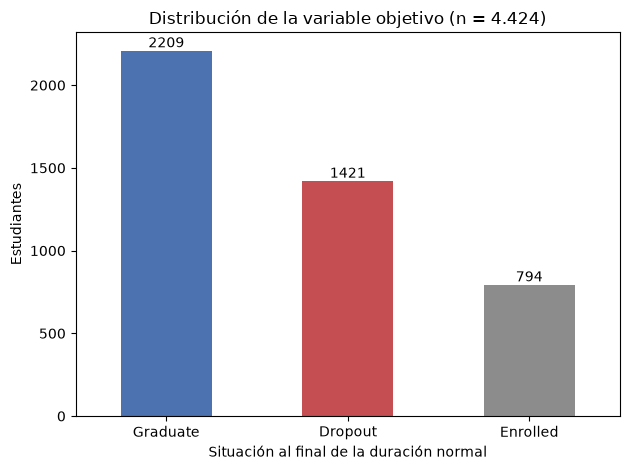

In [6]:
# 2.3 Figura: distribución de la etiqueta
ax = dist["n"].reindex(["Graduate", "Dropout", "Enrolled"]).plot.bar(rot=0, color=["#4c72b0", "#c44e52", "#8c8c8c"])
ax.set_xlabel("Situación al final de la duración normal")
ax.set_ylabel("Estudiantes")
ax.set_title("Distribución de la variable objetivo (n = 4.424)")
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout()
plt.show()

## 3. Grupos de variables y escenarios temporales

Los seis grupos siguen la clasificación de Realinho et al. (2022). Los escenarios son los del diseño del TFM:

- **E1**: lo disponible en la matrícula, sin las tres variables financieras de registro incierto.
- **E1+**: E1 más deudor, matrícula al día y becario (análisis de sensibilidad).
- **E2**: E1+ más el primer semestre.
- **E3**: E2 más el segundo semestre.

In [7]:
# 3.1 Diccionario de grupos
GRUPOS = {
    "Demográficas": ["Marital status", "Nacionality", "Displaced", "Gender", "Age at enrollment", "International"],
    "Socioeconómicas": ["Mother's qualification", "Father's qualification", "Mother's occupation",
                        "Father's occupation", "Educational special needs", "Debtor",
                        "Tuition fees up to date", "Scholarship holder"],
    "Macroeconómicas": ["Unemployment rate", "Inflation rate", "GDP"],
    "Académicas de matrícula": ["Application mode", "Application order", "Course",
                                "Daytime/evening attendance", "Previous qualification",
                                "Previous qualification (grade)", "Admission grade"],
    "Académicas 1.er semestre": [c for c in df.columns if c.startswith("Curricular units 1st sem")],
    "Académicas 2.º semestre": [c for c in df.columns if c.startswith("Curricular units 2nd sem")],
}
asignadas = [c for cols in GRUPOS.values() for c in cols]
assert len(asignadas) == 36 and set(asignadas) == set(df.columns) - {"Target", "dropout"}
pd.Series({g: len(c) for g, c in GRUPOS.items()}, name="n.º de variables").to_frame()

,n.º de variables
Demográficas,6
Socioeconómicas,8
Macroeconómicas,3
Académicas de matrícula,7
Académicas 1.er semestre,6
Académicas 2.º semestre,6


In [8]:
# 3.2 Variables por escenario
FINANCIERAS = ["Debtor", "Tuition fees up to date", "Scholarship holder"]
MATRICULA = GRUPOS["Demográficas"] + GRUPOS["Socioeconómicas"] + GRUPOS["Macroeconómicas"] + GRUPOS["Académicas de matrícula"]

ESCENARIOS = {
    "E1": [c for c in MATRICULA if c not in FINANCIERAS],
    "E1+": MATRICULA,
    "E2": MATRICULA + GRUPOS["Académicas 1.er semestre"],
    "E3": MATRICULA + GRUPOS["Académicas 1.er semestre"] + GRUPOS["Académicas 2.º semestre"],
}
pd.Series({e: len(c) for e, c in ESCENARIOS.items()}, name="n.º de predictores").to_frame()

,n.º de predictores
E1,21
E1+,24
E2,30
E3,36


## 4. Subgrupos para la evaluación de equidad

Tamaño y tasa de abandono por subgrupo. Los grupos pequeños (necesidades especiales, internacionales) dan estimaciones poco estables: conviene reportarlos con intervalos o agruparlos.

Codificación de la fuente: `Gender` 1 = hombre, 0 = mujer; en las binarias, 1 = sí. `Daytime/evening attendance` 1 = diurno.

In [9]:
# 4.1 Tamaño y tasa de abandono por subgrupo
SUBGRUPOS = ["Gender", "International", "Displaced", "Educational special needs",
             "Daytime/evening attendance", "Scholarship holder", "Debtor", "Tuition fees up to date"]
tablas = []
for col in SUBGRUPOS:
    t = df.groupby(col)["dropout"].agg(n="size", tasa_abandono="mean")
    t.index = pd.MultiIndex.from_product([[col], t.index], names=["variable", "valor"])
    tablas.append(t)
subgrupos = pd.concat(tablas)
subgrupos["%_muestra"] = (100 * subgrupos["n"] / len(df)).round(1)
subgrupos["tasa_abandono"] = subgrupos["tasa_abandono"].round(3)
subgrupos

n  tasa_abandono  %_muestra
variable                   valor                                
Gender                     0      2868          0.251       64.8
                           1      1556          0.451       35.2
International              0      4314          0.322       97.5
                           1       110          0.291        2.5
Displaced                  0      1998          0.376       45.2
                           1      2426          0.276       54.8
Educational special needs  0      4373          0.321       98.8
                           1        51          0.333        1.2
Daytime/evening attendance 0       483          0.429       10.9
                           1      3941          0.308       89.1
Scholarship holder         0      3325          0.387       75.2
                           1      1099          0.122       24.8
Debtor                     0      3921          0.283       88.6
                           1       503          0.620       11.4
Tuition fees up to date    0       528          0.866       11.9
                           1      3896          0.247       88.1

In [10]:
# 4.2 Edad de ingreso por tramos
edad = pd.cut(df["Age at enrollment"], bins=[0, 20, 25, 30, 40, float("inf")],
              labels=["≤20", "21–25", "26–30", "31–40", ">40"], include_lowest=True)
t = df.groupby(edad, observed=True)["dropout"].agg(n="size", tasa_abandono="mean").round(3)
t["%_muestra"] = (100 * t["n"] / len(df)).round(1)
print("Mediana de edad:", df["Age at enrollment"].median())
t

Mediana de edad: 20.0


,n,tasa_abandono,%_muestra
Age at enrollment,,,
≤20,2551,0.212,57.7
21–25,828,0.356,18.7
26–30,383,0.598,8.7
31–40,437,0.551,9.9
>40,225,0.507,5.1


In [11]:
# 4.3 Nacionalidad
nac = df["Nacionality"].value_counts()
print(f"Portuguesa (código 1): {nac.get(1, 0)} ({100 * nac.get(1, 0) / len(df):.1f} %)")
print(f"Otras {len(nac) - 1} nacionalidades: {len(df) - nac.get(1, 0)} estudiantes")

Portuguesa (código 1): 4314 (97.5 %)
Otras 20 nacionalidades: 110 estudiantes


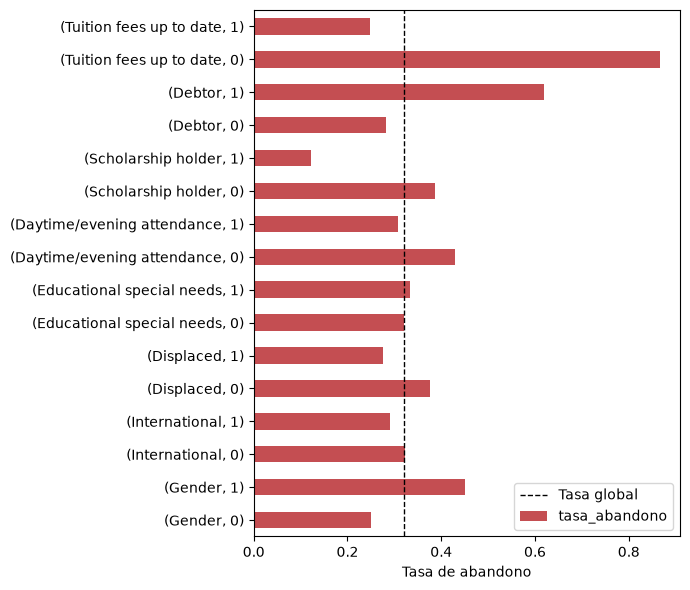

In [12]:
# 4.4 Figura: tasa de abandono por subgrupo
ax = subgrupos["tasa_abandono"].plot.barh(figsize=(7, 6), color="#c44e52")
ax.axvline(df["dropout"].mean(), ls="--", c="k", lw=1, label="Tasa global")
ax.set_xlabel("Tasa de abandono")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Registros sin unidades curriculares matriculadas

Hay estudiantes con 0 unidades matriculadas en ambos semestres. Una regla basada en unidades aprobadas los marcaría siempre como riesgo, así que hay que decidir cómo tratarlos antes de construir la regla.

In [13]:
# 5.1 Cero unidades matriculadas
c1, c2 = "Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"
cero = df[c1] == 0
print("Estudiantes con 0 matriculadas en el 1.er semestre:", int(cero.sum()))
print("Coincide con 0 en el 2.º semestre:", bool((cero == (df[c2] == 0)).all()))
print("Todas sus variables curriculares son 0:",
      bool((df.loc[cero, GRUPOS["Académicas 1.er semestre"] + GRUPOS["Académicas 2.º semestre"]] == 0).all().all()))
pd.crosstab(cero.rename("0 unidades matriculadas"), df["Target"], margins=True)

Estudiantes con 0 matriculadas en el 1.er semestre: 180
Coincide con 0 en el 2.º semestre: True
Todas sus variables curriculares son 0: True


Target,Dropout,Enrolled,Graduate,All
0 unidades matriculadas,,,,
False,1344,766,2134,4244
True,77,28,75,180
All,1421,794,2209,4424


In [14]:
# 5.2 Concentración en una titulación
print(df.loc[cero, "Course"].value_counts())
print("\nTotal de estudiantes en Course 171 (Animation and Multimedia Design):", int((df["Course"] == 171).sum()))
pd.crosstab(df["Course"] == 171, cero, rownames=["Course 171"], colnames=["0 unidades"])

Course
171    180
Name: count, dtype: int64

Total de estudiantes en Course 171 (Animation and Multimedia Design): 215


0 unidades,False,True
Course 171,,
False,4209,0
True,35,180


## 6. Variables macroeconómicas

Desempleo, inflación y PIB son valores de Portugal para el año de ingreso. Si solo hay pocas combinaciones distintas, funcionan como identificador de cohorte y no describen la situación individual del estudiante.

In [15]:
# 6.1 Combinaciones distintas
macro = GRUPOS["Macroeconómicas"]
g = df.groupby(macro)["dropout"].agg(n="size", tasa_abandono="mean").round(3)
print(len(g), "combinaciones distintas")
g

10 combinaciones distintas


,,,n,tasa_abandono
Unemployment rate,Inflation rate,GDP,,
7.6,2.6,0.32,571,0.354
8.9,1.4,3.51,368,0.277
9.4,-0.8,-3.12,533,0.326
10.8,1.4,1.74,525,0.347
11.1,0.6,2.02,414,0.283
12.4,0.5,1.79,445,0.240
12.7,3.7,-1.70,419,0.337
13.9,-0.3,0.79,390,0.303
15.5,2.8,-4.06,397,0.350


## 7. Modalidad de acceso

La UCI usa una perspectiva micro: cambiar de titulación o de institución cuenta como abandono. Aquí se cuantifican los ingresos por traslado o cambio, y otros grupos de acceso relevantes.

In [16]:
# 7.1 Grupos de modalidad de acceso
GRUPOS_ACCESO = {
    "Traslado o cambio de titulación/institución": [42, 43, 51, 57],
    "Ordenanza 533-A/99 (otro plan u otra institución)": [26, 27],
    "Titulación superior previa": [7, 44, 53],
    "Mayores de 23 años": [39],
}
filas = []
for nombre, cods in GRUPOS_ACCESO.items():
    m = df["Application mode"].isin(cods)
    filas.append({"grupo": nombre, "códigos": cods, "n": int(m.sum()),
                  "%_muestra": round(100 * m.mean(), 1), "tasa_abandono": round(df.loc[m, "dropout"].mean(), 3)})
pd.DataFrame(filas)

,grupo,códigos,n,%_muestra,tasa_abandono
0,Traslado o cambio de titulación/institución,"[42, 43, 51, 57]",449,10.1,0.376
1,Ordenanza 533-A/99 (otro plan u otra institución),"[26, 27]",2,0.0,1.000
2,Titulación superior previa,"[7, 44, 53]",387,8.7,0.393
3,Mayores de 23 años,[39],785,17.7,0.554


## 8. Poder discriminante univariado (exploratorio)

AUC con validación cruzada de un árbol poco profundo entrenado con una sola variable. **Solo es descriptivo**: se calcula sobre todo el conjunto, así que no puede usarse para seleccionar variables del experimento. Sirve para justificar que la regla tradicional se apoye en unidades aprobadas.

In [17]:
# 8.1 AUC por variable
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
grupo_de = {c: g for g, cols in GRUPOS.items() for c in cols}
auc = {}
for c in grupo_de:
    arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=SEED)
    auc[c] = cross_val_score(arbol, df[[c]], df["dropout"], cv=cv, scoring="roc_auc").mean()
ranking = pd.DataFrame({"AUC": pd.Series(auc).round(3), "grupo": pd.Series(grupo_de)}).sort_values("AUC", ascending=False)
ranking

,AUC,grupo
Curricular units 2nd sem (approved),0.861,Académicas 2.º semestre
Curricular units 1st sem (approved),0.822,Académicas 1.er semestre
Curricular units 2nd sem (grade),0.812,Académicas 2.º semestre
Curricular units 1st sem (grade),0.775,Académicas 1.er semestre
Curricular units 2nd sem (evaluations),0.698,Académicas 2.º semestre
Curricular units 1st sem (evaluations),0.677,Académicas 1.er semestre
Age at enrollment,0.672,Demográficas
Application mode,0.660,Académicas de matrícula
Tuition fees up to date,0.649,Socioeconómicas
Previous qualification (grade),0.643,Académicas de matrícula


In [18]:
# 8.2 Mejor AUC por grupo
ranking.groupby("grupo")["AUC"].agg(["max", "median"]).sort_values("max", ascending=False)

,max,median
grupo,,
Académicas 2.º semestre,0.861,0.6535
Académicas 1.er semestre,0.822,0.6445
Demográficas,0.672,0.5475
Académicas de matrícula,0.660,0.5810
Socioeconómicas,0.649,0.5775
Macroeconómicas,0.535,0.5310


## 9. Resumen de hallazgos

| Hallazgo | Implicación para el TFM |
|---|---|
| 4.424 registros, 36 predictores, 17 titulaciones, sin ausentes ni duplicados. | Cifras de 1.2 verificadas. |
| Abandono 1.421 (32,1 %); graduado 49,9 %; matriculado 17,9 %. | Desbalance moderado: priorizar *recall* y reportar la proporción de señalados (2.2.3). |
| E1 = 21 predictores; E1+ = 24; E2 = 30; E3 = 36. | Cada escenario añade un bloque completo al anterior. |
| Tasa de abandono 0,251 en mujeres y 0,451 en hombres; 0,212 con 20 años o menos y más de 0,50 a partir de 26. | Sexo y edad son ejes naturales para la auditoría de equidad. |
| 449 ingresos (10,1 %) por traslado o cambio, con tasa de abandono 0,376. | Ilustra la perspectiva micro: parte del abandono puede ser movilidad (2.1). |
| Subgrupos pequeños: necesidades especiales (51) e internacionales (110). | Equidad con intervalos de confianza o sin conclusiones fuertes en esos grupos. |
| Matrícula no al día: tasa de abandono 0,866; deudor: 0,620. | Posible fuga de información: se reservan para E1+ y E2. |
| 180 estudiantes con 0 unidades matriculadas, todos de Course 171. | Decidir su tratamiento antes de definir la regla. |
| Solo 10 combinaciones macroeconómicas. | Actúan como identificador de cohorte, no como dato individual (1.2). |
| Las unidades aprobadas del 2.º y 1.er semestre son las variables más discriminantes. | Justifica una regla basada en aprobadas en E2. |